# CALOR Y MAYORES EN MADRID

## Isócronas: el entorno de 15 minutos andando de cada centro de mayores

**Isócrona normal:** las calles que una persona mayor alcanza en 15 minutos andando a 0,8 m/s (720 m), por la red peatonal de OpenStreetMap.
**Uso en el proyecto:** cada isócrona define el área de influencia del centro, es decir, los hexágonos donde el modelo evaluará intervenciones.

## 1. Preparación y - importamos las librerías

In [1]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import networkx as nx

sys.path.append("../scrips")
from config import RUTA_RAW, RUTA_CLEAN, CRS_PROYECTO

**Decisión:** velocidad de 0,8 m/s, la velocidad media al caminar de las mujeres de 65 años o más (0,9 m/s en los hombres) según Asher y colaboradores (2012, Age and Ageing), con 3.145 personas mayores. Es un valor prudente, porque las mujeres son mayoría en los centros de mayores. Se usan 15 minutos, el criterio de la ciudad de 15 minutos. Distancia máxima: 0,8 × 15 × 60 = 720 m.

In [2]:
VELOCIDAD = 0.8
MINUTOS = 15
DISTANCIA_MAXIMA = VELOCIDAD * MINUTOS * 60
MARGEN_CALLE = 25
RADIO_SALIDA = 100

print("Distancia máxima:", DISTANCIA_MAXIMA, "m")

Distancia máxima: 720.0 m


**Observación:** la distancia máxima de la isócrona es de 720 m, lo que recorre una persona mayor en 15 minutos a 0,8 m/s.
**MARGEN_CALLE:** los metros que se añaden a cada lado de una calle alcanzada para formar el polígono (las aceras y los edificios que dan a ella).
**RADIO_SALIDA:** los cruces a menos de 100 m del centro son sus posibles salidas a la red peatonal.

- cargamos la red peatonal y la pasamos a metros

In [3]:
red = ox.load_graphml(RUTA_RAW + "osm/walk_graph_madrid.graphml")
red = ox.project_graph(red, to_crs=CRS_PROYECTO)
nodos, tramos = ox.graph_to_gdfs(red)

print("Nodos:", len(nodos), "- tramos:", len(tramos))
tramos["length"].describe()

Nodos: 220894 - tramos: 668278


count    668278.000000
mean         44.454306
std          68.294523
min           0.025377
25%           9.856405
50%          22.936808
75%          55.573998
max        5486.116700
Name: length, dtype: float64

**Observación:** la red tiene 220.894 cruces y 668.278 tramos, con una longitud mediana de 23 m; los tramos muy largos (hasta 5,5 km) son caminos por parques y zonas sin urbanizar.

- cargamos los centros y buscamos el cruce más cercano a cada uno

In [4]:
centros = gpd.read_file(RUTA_CLEAN + "centros_mayores.gpkg")
nodos_salida, distancias_nodo = ox.distance.nearest_nodes(red, X=centros["x"], Y=centros["y"], return_dist=True)
centros["nodo"] = nodos_salida
centros["dist_nodo"] = np.round(distancias_nodo, 1)

print("Centros:", len(centros))
centros["dist_nodo"].describe()

Centros: 439


count    439.000000
mean      26.827790
std       17.323574
min        3.100000
25%       15.750000
50%       22.300000
75%       33.800000
max      115.400000
Name: dist_nodo, dtype: float64

**Observación:** todos los centros tienen un cruce a menos de 115 m (mediana de 22 m), así que el punto de salida de cada isócrona es fiable.
**Decisión:** la isócrona no sale solo del cruce más cercano, sino de un "nodo puerta": un nodo virtual en la posición del centro, unido a cada cruce a menos de 100 m por un tramo de su distancia real. Al revisar las isócronas se detectó que el cruce más cercano en línea recta podía caer en un camino mal conectado con las calles (por ejemplo, en el Centro de Día Gentrya, un sendero del descampado vecino), lo que reducía mucho la isócrona. Con el nodo puerta, la persona sale por la mejor salida disponible y los 720 m se cuentan desde el centro. Con este cambio, la mediana de las áreas varía un 4,9 %, pero 43 centros (el 10 %) cambian más de un 30 %.

- funciones para calcular la isócrona desde el nodo puerta de cada centro

In [5]:
def nodos_de_salida(punto):
    """Devuelve los cruces a menos de RADIO_SALIDA m del centro; si no hay ninguno, el más cercano."""
    posiciones = nodos.sindex.query(punto.buffer(RADIO_SALIDA), predicate="intersects")
    if len(posiciones) == 0:
        return [ox.distance.nearest_nodes(red, X=punto.x, Y=punto.y)]
    return list(nodos.index[posiciones])


def calcular_isocrona(punto, peso):
    """Devuelve el polígono de las calles alcanzadas desde la puerta del centro y el nº de cruces alcanzados."""
    salidas = nodos_de_salida(punto)
    red.add_node("puerta")
    for nodo in salidas:
        distancia = punto.distance(nodos.loc[nodo, "geometry"])
        red.add_edge("puerta", nodo, **{peso: distancia})

    alcanzados = nx.single_source_dijkstra_path_length(red, "puerta", cutoff=DISTANCIA_MAXIMA, weight=peso)
    red.remove_node("puerta")

    tramos_alcanzados = tramos[
        tramos.index.get_level_values("u").isin(alcanzados) &
        tramos.index.get_level_values("v").isin(alcanzados)
    ]
    return tramos_alcanzados.buffer(MARGEN_CALLE).union_all(), len(alcanzados) - 1

## 2. Cálculo de las isócronas y - recorremos la red desde cada centro hasta 720 m y formamos el polígono con las calles alcanzadas

In [6]:
poligonos = []
n_nodos = []

for punto in centros.geometry:
    poligono, n_alcanzados = calcular_isocrona(punto, "length")
    poligonos.append(poligono)
    n_nodos.append(n_alcanzados)

isocronas = gpd.GeoDataFrame(
    centros[["codigo", "nombre", "tipo_centro", "plazas", "dist_nodo"]].copy(),
    geometry=poligonos,
    crs=CRS_PROYECTO
)
isocronas["n_nodos"] = n_nodos
isocronas["area_km2"] = (isocronas.area / 1_000_000).round(3)
isocronas[["n_nodos", "area_km2"]].describe()

,n_nodos,area_km2
count,439.000000,439.000000
mean,713.152620,0.750697
std,330.746619,0.179993
min,82.000000,0.189000
25%,482.000000,0.647000
50%,702.000000,0.790000
75%,882.500000,0.879000
max,2064.000000,1.117000


**Observación:** la isócrona media ocupa 0,75 km², el 46 % del círculo de 720 m, porque el recorrido sigue las calles. Su tamaño varía de 0,19 a 1,12 km² según la densidad de calles y las barreras. Saliendo desde el nodo puerta, los centros alcanzan de media 713 cruces (antes, 665).

- revisamos las cinco isócronas más pequeñas

In [7]:
isocronas.nsmallest(5, "area_km2")[["nombre", "tipo_centro", "dist_nodo", "n_nodos", "area_km2"]]

,nombre,tipo_centro,dist_nodo,n_nodos,area_km2
47,"DOCTOR GONZALEZ BUENO, RESIDENCIA DE PERSONAS ...",residencia,12.4,91,0.189
90,"CASER RESIDENCIAL SANTA HORTENSIA, RESIDENCIA ...",residencia,112.3,192,0.246
377,RESIDENCIA DE MAYORES LA NUEVA FLORIDA,residencia,49.0,149,0.250
88,"LOS ENEBROS, RESIDENCIA PERSONAS MAYORES",residencia,21.9,138,0.279
36,"JUAN XXIII (ARAVACA), RESIDENCIA PERSONAS MAYORES",residencia,59.2,155,0.288


**Observación:** las isócronas más pequeñas (0,19-0,29 km²) son todas residencias. Ahora salen desde la mejor salida disponible, así que su tamaño reducido se debe a barreras reales o a una red escasa en su entorno.

## 3. Hexágonos de cada isócrona y - asignamos a cada isócrona los hexágonos urbanos cuyo centro cae dentro

In [8]:
hexagonos_todos = gpd.read_file(RUTA_CLEAN + "hexagonos_h3.gpkg")
hexagonos = hexagonos_todos[hexagonos_todos["urbano"]].copy()
centroides = gpd.GeoDataFrame(hexagonos[["h3"]], geometry=hexagonos.centroid, crs=CRS_PROYECTO)

centros_hexagonos = gpd.sjoin(centroides, isocronas[["codigo", "geometry"]], how="inner", predicate="within")
centros_hexagonos = centros_hexagonos[["codigo", "h3"]].reset_index(drop=True)

hexagonos_por_centro = centros_hexagonos.groupby("codigo").size()
print("Pares centro-hexágono:", len(centros_hexagonos))
print("Hexágonos distintos en alguna isócrona:", centros_hexagonos["h3"].nunique())
hexagonos_por_centro.describe()

Pares centro-hexágono: 3014
Hexágonos distintos en alguna isócrona: 1067


count    438.000000
mean       6.881279
std        2.188919
min        1.000000
25%        6.000000
50%        7.000000
75%        8.000000
max       11.000000
dtype: float64

**Observación:** hay 3.014 pares centro-hexágono y 1.067 hexágonos distintos. Cada isócrona tiene de media 6,9 hexágonos. Un centro se queda sin ninguno.

- revisamos si algún centro se queda sin hexágonos

In [9]:
centros_sin_hexagono = set(isocronas["codigo"]) - set(centros_hexagonos["codigo"])
print("Centros sin ningún hexágono en su isócrona:", len(centros_sin_hexagono))

Centros sin ningún hexágono en su isócrona: 1


**Observación:** 1 centro se queda sin hexágonos, porque sus isócronas son tan pequeñas que ningún centro de hexágono cae dentro.

**Decisión:** se añade siempre a cada isócrona el hexágono en el que está el propio centro. Así los 3 centros con isócronas muy pequeñas (sin ningún centro de hexágono dentro) tienen al menos un hexágono, y en el resto se garantiza que su hexágono cuenta. Es coherente con el simulador, que trabaja con el hexágono de cada centro.

- añadimos el hexágono de cada centro y quitamos los pares repetidos

In [10]:
hexagono_propio = gpd.sjoin(centros[["codigo", "geometry"]], hexagonos[["h3", "geometry"]], how="inner", predicate="within")
hexagono_propio = hexagono_propio[["codigo", "h3"]]

centros_hexagonos = pd.concat([centros_hexagonos, hexagono_propio], ignore_index=True)
centros_hexagonos = centros_hexagonos.drop_duplicates().reset_index(drop=True)

hexagonos_por_centro = centros_hexagonos.groupby("codigo").size()
print("Pares centro-hexágono:", len(centros_hexagonos))
print("Hexágonos distintos en alguna isócrona:", centros_hexagonos["h3"].nunique())
print("Centros sin hexágonos:", len(set(isocronas["codigo"]) - set(centros_hexagonos["codigo"])))
hexagonos_por_centro.describe()

Pares centro-hexágono: 3083
Hexágonos distintos en alguna isócrona: 1119
Centros sin hexágonos: 0


count    439.000000
mean       7.022779
std        2.105533
min        1.000000
25%        6.000000
50%        7.000000
75%        8.000000
max       11.000000
dtype: float64

**Observación:** al añadir el hexágono de cada centro, los 439 tienen al menos uno. Se suman 69 pares (de 3.014 a 3.083) y 52 hexágonos candidatos (de 1.067 a 1.119). Cada isócrona tiene ahora de media 7 hexágonos.

## 4. Comprobación visual y - dibujamos la isócrona de tres centros con la red y los hexágonos

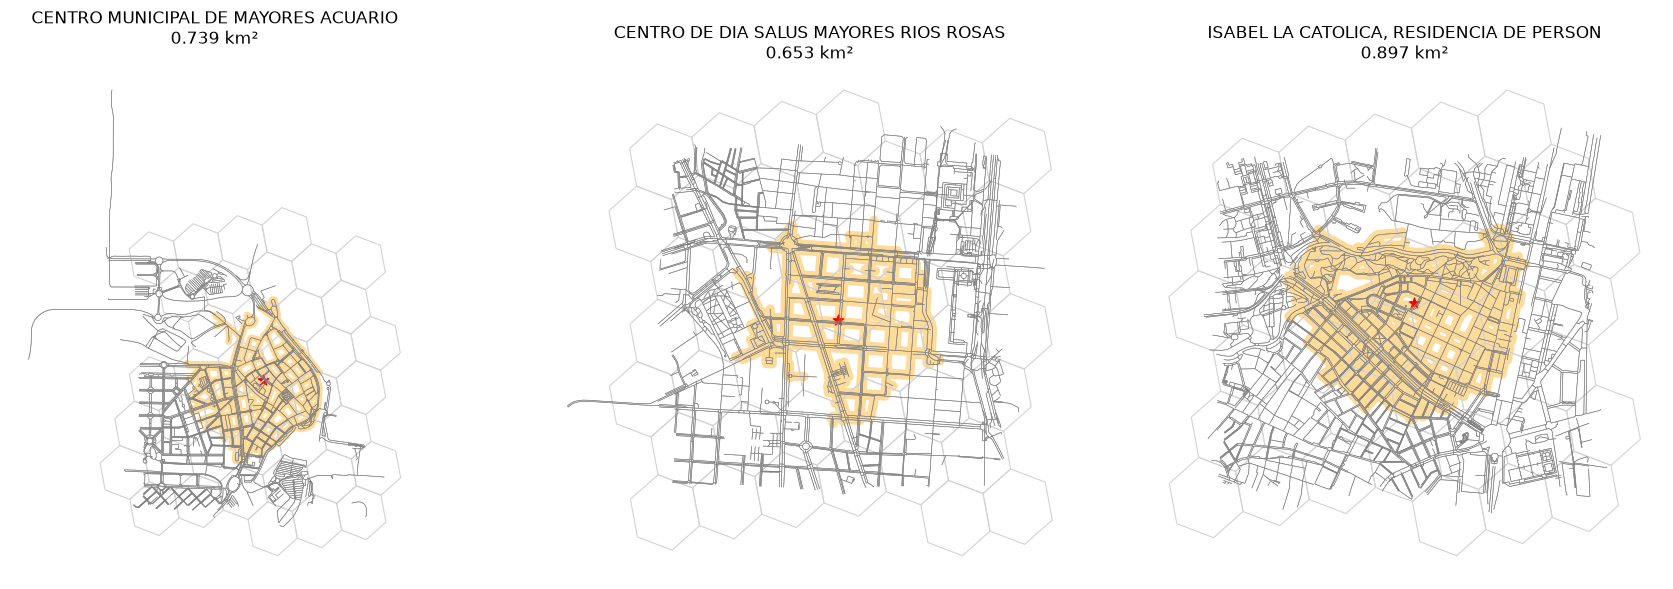

In [11]:
ejemplos = isocronas.sample(3, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for eje, (_, fila) in zip(axes, ejemplos.iterrows()):
    xmin, ymin, xmax, ymax = fila.geometry.buffer(300).bounds
    hexagonos.cx[xmin:xmax, ymin:ymax].boundary.plot(ax=eje, color="lightgrey", linewidth=0.8)
    tramos.cx[xmin:xmax, ymin:ymax].plot(ax=eje, color="grey", linewidth=0.4)
    gpd.GeoSeries([fila.geometry], crs=CRS_PROYECTO).plot(ax=eje, color="orange", alpha=0.4)
    centros[centros["codigo"] == fila["codigo"]].plot(ax=eje, color="red", markersize=60, marker="*")
    eje.set_title(f"{fila['nombre'][:40]}\n{fila['area_km2']} km²")
    eje.set_axis_off()
plt.tight_layout()
plt.show()

**Observación del mapa al azar:** en los tres centros elegidos al azar, la isócrona sigue la forma de las calles: es más compacta en las cuadrículas densas, como Ríos Rosas, y se estira a lo largo de las vías principales. Con áreas de 0,65 a 0,85 km², ocupan entre 6 y 8 hexágonos del entorno de cada centro

- guardamos las isócronas y la relación centro-hexágono

In [12]:
isocronas.to_file(RUTA_CLEAN + "isocronas_normales.gpkg", driver="GPKG")
centros_hexagonos.to_csv(RUTA_CLEAN + "centros_hexagonos.csv", index=False)

## 5. Isócrona confortable

**Decisión:** cada tramo de calle tiene una "longitud vivida" que penaliza el calor, siguiendo la formulación de CoolWalks (Wolf y colaboradores, 2024): coste = longitud × (1 + (α − 1) × calor del tramo), donde α es la aversión al calor (un metro con el máximo calor se vive como α metros frescos). Es la idea del método isocalor (Huber y colaboradores, 2025): una isócrona que evita la exposición al calor. Se usa α = 1,5 como valor central (el límite de lo realista según CoolWalks, adecuado para personas mayores, más sensibles al calor) y se comprueba la sensibilidad con α = 1,25 y α = 2.

**Limitación:** CoolWalks usa la sombra de cada calle; aquí se usa la temperatura de superficie del hexágono por el que pasa el tramo como indicador del calor.

- asignamos a cada tramo la temperatura del hexágono en el que está su punto medio

In [13]:
puntos_medios = gpd.GeoDataFrame(geometry=tramos.geometry.interpolate(0.5, normalized=True), crs=CRS_PROYECTO)
puntos_medios = gpd.sjoin_nearest(puntos_medios, hexagonos_todos[["lst", "geometry"]], how="left")
puntos_medios = puntos_medios[~puntos_medios.index.duplicated()]
tramos["lst"] = puntos_medios["lst"]

print("Tramos sin temperatura:", tramos["lst"].isnull().sum())
tramos["lst"].describe()

Tramos sin temperatura: 0


count    668278.000000
mean         44.910246
std           2.529407
min          34.618230
25%          43.262755
50%          44.622232
75%          46.478672
max          55.738333
Name: lst, dtype: float64

**Observación:** todos los tramos tienen temperatura; la mediana es de 44,6 °C y el rango va de 34,6 a 55,7 °C.

**Decisión:** el calor del tramo se pasa a una escala de 0 a 1 entre los percentiles 5 y 95 de la temperatura de los hexágonos urbanos: 0 es una calle fresca y 1 una calle muy caliente. Usar percentiles en lugar del mínimo y el máximo evita que unos pocos valores extremos (agua, pistas del aeropuerto) compriman la escala.

- calculamos el calor de cada tramo entre 0 y 1

In [14]:
lst_p5 = hexagonos["lst"].quantile(0.05)
lst_p95 = hexagonos["lst"].quantile(0.95)
tramos["calor"] = ((tramos["lst"] - lst_p5) / (lst_p95 - lst_p5)).clip(0, 1)

print("Percentil 5:", round(lst_p5, 2), "°C - percentil 95:", round(lst_p95, 2), "°C")
tramos["calor"].describe()

Percentil 5: 41.09 °C - percentil 95: 50.46 °C


count    668278.000000
mean          0.413084
std           0.249242
min           0.000000
25%           0.232070
50%           0.377224
75%           0.575439
max           1.000000
Name: calor, dtype: float64

**Observación:** el calor de cada tramo se expresa en una escala sin unidades de 0 a 1, donde 0 corresponde a 41,1 °C o menos (percentil 5) y 1 a 50,5 °C o más (percentil 95). El tramo típico tiene un calor de 0,38, que equivale a unos 44,6 °C.

- función que calcula el polígono de la isócrona de un centro con un peso dado (longitud o coste vivido)

- calculamos la isócrona confortable de cada centro con los tres valores de α y su % de confort

In [16]:
valores_alfa = [1.25, 1.5, 2]
poligonos_central = []

for alfa in valores_alfa:
    nombre_peso = f"coste_{alfa}"
    tramos[nombre_peso] = tramos["length"] * (1 + (alfa - 1) * tramos["calor"])
    nx.set_edge_attributes(red, tramos[nombre_peso].to_dict(), nombre_peso)

    areas = []
    for punto in centros.geometry:
        poligono, _ = calcular_isocrona(punto, nombre_peso)
        areas.append(poligono.area / 1_000_000)
        if alfa == 1.5:
            poligonos_central.append(poligono)

    isocronas[f"area_conf_{alfa}"] = np.round(areas, 3)
    isocronas[f"pct_confort_{alfa}"] = (isocronas[f"area_conf_{alfa}"] / isocronas["area_km2"] * 100).round(1)
    print(f"α = {alfa}: terminado")

isocronas[["pct_confort_1.25", "pct_confort_1.5", "pct_confort_2"]].describe()

α = 1.25: terminado
α = 1.5: terminado
α = 2: terminado


,pct_confort_1.25,pct_confort_1.5,pct_confort_2
count,439.000000,439.000000,439.000000
mean,87.631435,77.916401,63.902961
std,5.159600,8.097593,11.217388
min,66.200000,47.600000,30.200000
25%,84.500000,73.150000,55.900000
50%,87.900000,77.400000,62.500000
75%,91.200000,83.200000,71.350000
max,100.000000,96.900000,92.800000


**Observación:** con el valor central (α = 1,5), un centro típico puede recorrer sin exceso de calor el 78 % de su isócrona normal, y el peor, el 47,6 %. Con α = 1,25 la media sube al 88 % y con α = 2 baja al 64 %. El nivel depende del supuesto, pero el orden de los centros apenas cambia

- comprobamos si el orden de los centros según su % de confort cambia con el valor de α (correlación de Spearman)

In [17]:
isocronas[["pct_confort_1.25", "pct_confort_1.5", "pct_confort_2"]].corr(method="spearman").round(3)

,pct_confort_1.25,pct_confort_1.5,pct_confort_2
pct_confort_1.25,1.000,0.934,0.896
pct_confort_1.5,0.934,1.000,0.952
pct_confort_2,0.896,0.952,1.000


Observación: el orden de los centros según su confort es casi el mismo con los tres valores de α (correlaciones de 0,90 a 0,95). α cambia el nivel de confort, pero no qué centros están peor.

- mapa de tres centros con la isócrona normal y la confortable (α = 1,5)

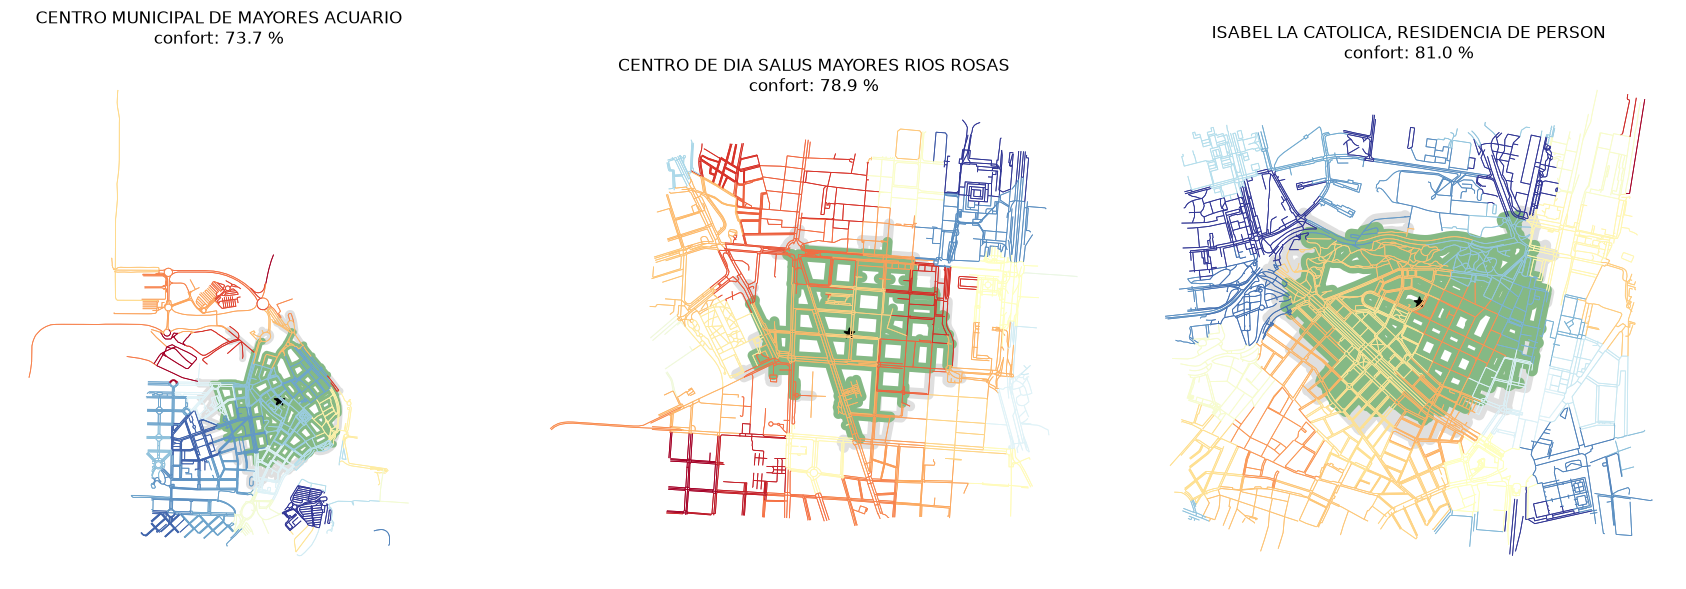

In [18]:
isocronas_confortables = gpd.GeoDataFrame(
    isocronas[["codigo", "nombre", "tipo_centro", "plazas", "area_km2", "area_conf_1.5", "pct_confort_1.5"]].copy(),
    geometry=poligonos_central,
    crs=CRS_PROYECTO
)

ejemplos = isocronas_confortables.sample(3, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for eje, (indice, fila) in zip(axes, ejemplos.iterrows()):
    xmin, ymin, xmax, ymax = isocronas.loc[indice, "geometry"].buffer(300).bounds
    tramos.cx[xmin:xmax, ymin:ymax].plot(ax=eje, column="calor", cmap="RdYlBu_r", linewidth=0.6)
    gpd.GeoSeries([isocronas.loc[indice, "geometry"]], crs=CRS_PROYECTO).plot(ax=eje, color="grey", alpha=0.25)
    gpd.GeoSeries([fila.geometry], crs=CRS_PROYECTO).plot(ax=eje, color="green", alpha=0.4)
    centros[centros["codigo"] == fila["codigo"]].plot(ax=eje, color="black", markersize=60, marker="*")
    eje.set_title(f"{fila['nombre'][:40]}\nconfort: {fila['pct_confort_1.5']} %")
    eje.set_axis_off()
plt.tight_layout()
plt.show()

Observación: la isócrona confortable (verde) es menor que la normal (gris) y se recorta sobre todo por las calles más calientes (rojas), mientras que mantiene las frescas (azules).

**Conclusión:** no existe un valor exacto de cuánto molesta el calor a una persona mayor al caminar (α), así que se probaron tres valores tomados del estudio CoolWalks (Wolf y colaboradores, 2024, arXiv:2405.01225), que considera realistas los valores de hasta 1,5. Cada uno da un porcentaje de confort distinto, pero los centros que salen peor son prácticamente los mismos con los tres valores de alfa (correlación de Spearman de 0,90 a 0,95). Por tanto, la elección de α no cambia qué centros necesitan actuar primero.

- guardamos las isócronas confortables y añadimos el % de confort a las normales

In [19]:
isocronas_confortables.to_file(RUTA_CLEAN + "isocronas_confortables.gpkg", driver="GPKG")
isocronas.to_file(RUTA_CLEAN + "isocronas_normales.gpkg", driver="GPKG")

In [ ]:
- comprobamos que el script scrips/isocronas.py da exactamente el mismo resultado que el notebook

In [20]:
from isocronas import calcular_isocronas

isocronas_script, confortables_script, centros_hexagonos_script = calcular_isocronas()
print("Isócronas normales:", isocronas.equals(isocronas_script))
print("Isócronas confortables:", isocronas_confortables.equals(confortables_script))
print("Relación centro-hexágono:", centros_hexagonos.equals(centros_hexagonos_script))

Isócronas normales: True
Isócronas confortables: True
Relación centro-hexágono: True
